# Project 1 · Smart Society Security System (Face Recognition)

**Assignment:** use the laptop webcam to capture faces of people entering, compare them against a **pre-registered database of residents**, and **allow entry if recognised (green message), otherwise reject (red message)**.
**Tech stack:** OpenCV + Python + a face-recognition model + **SQLite** database.
**Deliverables checklist:**
- [ ] working prototype with the laptop webcam (Section 7)
- [ ] database of **at least 20 registered faces** (Sections 3–4)
- [ ] report on **accuracy, false positives and false negatives** (Section 8 writes the numbers for you)

> This notebook already ran once in **demo mode** on sample photos, so you can see every output. For your submission, put your residents' photos in `data/residents/` and test photos in `data/test/`, set `DEMO = False`, and run everything again.

## How it works (explain this in your report)

```
webcam frame ─► 1. DETECT faces (YuNet) ─► 2. ALIGN + EMBED: each face → 128 numbers (SFace)
                                                      │
               4. DECIDE: best similarity ≥ threshold? ◄── 3. COMPARE with every resident's
                  yes → "ENTRY ALLOWED" (green)            stored embedding (cosine similarity)
                  no  → "ENTRY REJECTED" (red) → log to the database
```

- **Detection** finds *where* faces are (a box + 5 landmarks: eyes, nose, mouth corners).
- **Embedding** is the key idea behind **FaceNet**-style recognition: a CNN maps a face to a vector so that **the same person's photos land close together and different people land far apart**. Recognition becomes "is this vector close to a stored one?"
- **Cosine similarity**: 1 = identical direction, 0 = unrelated. OpenCV recommends **≥ 0.363** as "same person" for SFace. We tune this in Section 8.

**Why these models?** The brief mentions dlib/FaceNet. OpenCV's **SFace** is a FaceNet-style embedding model and **YuNet** is a fast CNN face detector. Both ship inside `opencv-python`, so there's no dlib/CMake compilation on Windows. (The `face_recognition` package wraps dlib's model the same way; see the note at the end.)

## 0 · Setup
```
pip install opencv-python numpy pandas matplotlib
```
Folder layout this notebook expects (created automatically):
```
project/
├── project1_smart_security_face_recognition.ipynb   ← this notebook
├── models/                      ← face models (downloaded automatically, about 39 MB)
├── data/residents/<Name>/*.jpg  ← 3-5 clear photos per resident (20+ residents)
├── data/test/<Name>/*.jpg       ← DIFFERENT photos of residents (for the accuracy report)
├── data/test/unknown/*.jpg      ← photos of people who are NOT residents
├── security.db                  ← SQLite database (created by the notebook)
└── report/                      ← evaluation tables and plots for your report
```

In [1]:
%matplotlib inline
import os, glob, sqlite3, datetime, urllib.request
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)     # hide OpenCV's info/warning messages

DEMO = True                   # True: build a small demo dataset from public sample photos. False: use YOUR data/ folders.
THRESHOLD = 0.363             # cosine similarity needed to accept someone (tune it in Section 8)
DB_PATH = "demo_security.db" if DEMO else "security.db"
if DEMO and os.path.exists(DB_PATH):
    os.remove(DB_PATH)        # start the demo from a clean database every run (your real security.db is never deleted)
for d in ["models", "data/residents", "data/test/unknown", "report"]:
    os.makedirs(d, exist_ok=True)
print("OpenCV", cv2.__version__, "| demo mode:", DEMO)

OpenCV 5.0.0 | demo mode: True


## 1 · Download the two face models (once)

In [2]:
MODELS = {
    "models/face_detection_yunet_2023mar.onnx":
        "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
    "models/face_recognition_sface_2021dec.onnx":
        "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx",
}
for path, url in MODELS.items():
    if not os.path.exists(path) or os.path.getsize(path) < 100_000:
        print("downloading", os.path.basename(path), "...")
        urllib.request.urlretrieve(url, path)
    print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")

models/face_detection_yunet_2023mar.onnx: 0.2 MB
models/face_recognition_sface_2021dec.onnx: 38.7 MB


## 2 · The face engine

In [3]:
class FaceEngine:
    """Detect faces (YuNet) and turn each face into a 128-number 'faceprint' (SFace)."""

    def __init__(self, detector_path, recognizer_path, min_face=60, score_threshold=0.8):
        self.detector = cv2.FaceDetectorYN.create(detector_path, "", (320, 320), score_threshold, 0.3, 5000)
        self.recognizer = cv2.FaceRecognizerSF.create(recognizer_path, "")
        self.min_face = min_face          # ignore faces narrower than this (too small to recognise reliably)

    def detect(self, image):
        """Return an array of faces; each row = [x, y, w, h, 5 landmark points (10 numbers), score]."""
        h, w = image.shape[:2]
        self.detector.setInputSize((w, h))
        _, faces = self.detector.detect(image)
        if faces is None:
            return np.zeros((0, 15), np.float32)
        return faces[faces[:, 2] >= self.min_face]

    def embed(self, image, face):
        """Align the face using its landmarks, then compute a unit-length 128-d embedding."""
        aligned = self.recognizer.alignCrop(image, face)
        vec = self.recognizer.feature(aligned).flatten().astype(np.float32)
        return vec / np.linalg.norm(vec)

    def largest_face(self, image):
        faces = self.detect(image)
        if len(faces) == 0:
            return None
        return faces[np.argmax(faces[:, 2] * faces[:, 3])]

engine = FaceEngine("models/face_detection_yunet_2023mar.onnx", "models/face_recognition_sface_2021dec.onnx")
print("engine ready")

engine ready


### Demo data (only when `DEMO = True`)
We download a few **public sample photos that ship with open-source libraries** (OpenCV, matplotlib, Ultralytics and the `face_recognition` project, whose examples are public-domain official portraits). The sources are listed in the table printed below. From them we build:
- **6 demo "residents"** (Person_A … Person_F), each registered from one photo plus two altered copies,
- **test photos**: for Person_A and Person_B, **genuinely different photos** (other days, other lighting); for the others, altered copies (darker, blurred, mirrored, smaller),
- **4 "unknown visitors"** who are *not* registered (two clear portraits and two small faces from a street photo).

⚠️ Altered copies of a registration photo are easier than real new photos, so treat demo accuracy as **optimistic**. Your own evaluation must use **different photos** for every resident.

In [4]:
def augment(img, kind):
    if kind == "dark":    return cv2.convertScaleAbs(img, alpha=0.55, beta=0)
    if kind == "bright":  return cv2.convertScaleAbs(img, alpha=1.2, beta=35)
    if kind == "blur":    return cv2.GaussianBlur(img, (5, 5), 0)
    if kind == "mirror":  return cv2.flip(img, 1)
    if kind == "small":   return cv2.resize(cv2.resize(img, None, fx=0.5, fy=0.5), None, fx=2, fy=2)
    if kind == "rotate":
        h, w = img.shape[:2]
        return cv2.warpAffine(img, cv2.getRotationMatrix2D((w / 2, h / 2), 10, 1.0), (w, h), borderMode=cv2.BORDER_REFLECT)
    return img

SOURCES = {   # file name -> where it comes from (all public sample images used by open-source projects)
    "obama.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama.jpg",
    "obama2.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama2.jpg",
    "obama3.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/tests/test_images/obama3.jpg",
    "biden.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/biden.jpg",
    "two_people.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/two_people.jpg",
    "alex-lacamoire.png": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/alex-lacamoire.png",
    "lin-manuel-miranda.png": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/lin-manuel-miranda.png",
    "lena.jpg": "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/lena.jpg",
    "grace_hopper.jpg": "https://raw.githubusercontent.com/matplotlib/matplotlib/main/lib/matplotlib/mpl-data/sample_data/grace_hopper.jpg",
    "zidane.jpg": "https://github.com/ultralytics/assets/releases/download/v0.0.0/zidane.jpg",
    "bus.jpg": "https://github.com/ultralytics/assets/releases/download/v0.0.0/bus.jpg",
}

def face_crops(img, pad=0.7, out=320, min_face=30):
    # cut a square around every face (largest first) and resize it, like a photo taken at the door
    old = engine.min_face; engine.min_face = min_face
    faces = engine.detect(img); engine.min_face = old
    crops = []
    for f in faces[np.argsort(-faces[:, 2])]:
        x, y, w, h = f[:4]; cx, cy = x + w / 2, y + h / 2; s = max(w, h) * (1 + pad)
        x0, y0, x1, y1 = int(max(cx - s / 2, 0)), int(max(cy - s / 2, 0)), int(cx + s / 2), int(cy + s / 2)
        crops.append(cv2.resize(img[y0:y1, x0:x1], (out, out)))
    return crops

def build_demo_data(root="demo_data"):
    if os.path.exists(os.path.join(root, "done.txt")):
        return root
    src = os.path.join(root, "source"); os.makedirs(src, exist_ok=True)
    for name, url in SOURCES.items():
        if not os.path.exists(os.path.join(src, name)):
            urllib.request.urlretrieve(url, os.path.join(src, name))
    load = lambda n: cv2.imread(os.path.join(src, n))
    zidane = face_crops(load("zidane.jpg"), pad=0.5)
    two = face_crops(load("two_people.jpg"), pad=0.5)
    registration = {"Person_A": load("obama.jpg"), "Person_B": load("biden.jpg"), "Person_C": load("lena.jpg"),
                    "Person_D": load("grace_hopper.jpg"), "Person_E": zidane[0], "Person_F": zidane[1]}
    # genuinely different photos for A and B; altered copies for the rest
    tests = {"Person_A": [load("obama2.jpg"), load("obama3.jpg"), augment(load("obama2.jpg"), "dark")],
             "Person_B": [], "Person_C": [], "Person_D": [], "Person_E": [], "Person_F": []}
    for crop in two:                                       # two_people.jpg = A and B in a new photo
        e = engine.embed(crop, engine.largest_face(crop))
        ra = engine.embed(registration["Person_A"], engine.largest_face(registration["Person_A"]))
        tests["Person_A" if e @ ra > 0.5 else "Person_B"].append(crop)
    tests["Person_B"].append(augment(tests["Person_B"][0], "small"))
    for name in ["Person_C", "Person_D", "Person_E", "Person_F"]:
        tests[name] = [augment(registration[name], k) for k in ["dark", "blur", "mirror", "small"]]
    strangers = [load("alex-lacamoire.png"), load("lin-manuel-miranda.png")] + face_crops(load("bus.jpg"), pad=0.6)[:2]
    for name, img in registration.items():
        reg = os.path.join(root, "residents", name); os.makedirs(reg, exist_ok=True)
        for kind in ["none", "bright", "rotate"]:
            cv2.imwrite(os.path.join(reg, f"{kind}.jpg"), augment(img, kind))
        tst = os.path.join(root, "test", name); os.makedirs(tst, exist_ok=True)
        for k, img2 in enumerate(tests[name]):
            cv2.imwrite(os.path.join(tst, f"test_{k}.jpg"), img2)
    unk = os.path.join(root, "test", "unknown"); os.makedirs(unk, exist_ok=True)
    for k, img in enumerate(strangers):
        cv2.imwrite(os.path.join(unk, f"visitor_{k}.jpg"), img)
    open(os.path.join(root, "done.txt"), "w").write("ok")
    return root

DATA = build_demo_data() if DEMO else "data"
print("using data folder:", DATA)
for split in ["residents", "test"]:
    counts = {p: len(os.listdir(os.path.join(DATA, split, p))) for p in sorted(os.listdir(os.path.join(DATA, split)))}
    print(f"{split:<10}", counts)
if DEMO:
    print("\nimage sources:"); [print("  ", n, "<-", u) for n, u in SOURCES.items()]

using data folder: demo_data
residents  {'Person_A': 3, 'Person_B': 3, 'Person_C': 3, 'Person_D': 3, 'Person_E': 3, 'Person_F': 3}
test       {'Person_A': 4, 'Person_B': 2, 'Person_C': 4, 'Person_D': 4, 'Person_E': 4, 'Person_F': 4, 'unknown': 4}

image sources:
   obama.jpg <- https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama.jpg
   obama2.jpg <- https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama2.jpg
   obama3.jpg <- https://raw.githubusercontent.com/ageitgey/face_recognition/master/tests/test_images/obama3.jpg
   biden.jpg <- https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/biden.jpg
   two_people.jpg <- https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/two_people.jpg
   alex-lacamoire.png <- https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/alex-lacamoire.png
   lin-manuel-miranda.png <- https://raw.githubusercontent.com/ageitgey/face_recogni

## 3 · The SQLite database

Two tables:
- `residents`: one row per person (id, name, flat number, registration time),
- `embeddings`: one or more 128-number faceprints per resident (several photos make recognition more robust),
- plus `access_log`: every entry attempt with time, decision, best match and score. This is your audit trail and the data for false-positive analysis.

Embeddings are stored as raw bytes (`BLOB`). **We never need to store the photos themselves**, which is better for privacy.

In [5]:
def connect(path=DB_PATH):
    con = sqlite3.connect(path)
    con.executescript('''
        CREATE TABLE IF NOT EXISTS residents (
            id INTEGER PRIMARY KEY AUTOINCREMENT, name TEXT UNIQUE NOT NULL,
            flat TEXT, registered_at TEXT);
        CREATE TABLE IF NOT EXISTS embeddings (
            id INTEGER PRIMARY KEY AUTOINCREMENT, resident_id INTEGER NOT NULL REFERENCES residents(id),
            vector BLOB NOT NULL, source TEXT);
        CREATE TABLE IF NOT EXISTS access_log (
            id INTEGER PRIMARY KEY AUTOINCREMENT, time TEXT, decision TEXT,
            best_match TEXT, score REAL, source TEXT);
    ''')
    return con

def add_resident(con, name, vectors, flat="", sources=None):
    cur = con.execute("INSERT OR IGNORE INTO residents(name, flat, registered_at) VALUES (?, ?, ?)",
                      (name, flat, datetime.datetime.now().isoformat(timespec="seconds")))
    rid = con.execute("SELECT id FROM residents WHERE name = ?", (name,)).fetchone()[0]
    con.execute("DELETE FROM embeddings WHERE resident_id = ?", (rid,))          # re-registering replaces old faceprints
    for k, v in enumerate(vectors):
        con.execute("INSERT INTO embeddings(resident_id, vector, source) VALUES (?, ?, ?)",
                    (rid, v.astype(np.float32).tobytes(), (sources or [""] * len(vectors))[k]))
    con.commit()

def load_gallery(con):
    rows = con.execute("SELECT r.name, e.vector FROM embeddings e JOIN residents r ON r.id = e.resident_id").fetchall()
    names = [r[0] for r in rows]
    vectors = np.stack([np.frombuffer(r[1], dtype=np.float32) for r in rows]) if rows else np.zeros((0, 128), np.float32)
    return names, vectors

def log_access(con, decision, best_match, score, source):
    con.execute("INSERT INTO access_log(time, decision, best_match, score, source) VALUES (?, ?, ?, ?, ?)",
                (datetime.datetime.now().isoformat(timespec="seconds"), decision, best_match, float(score), source))
    con.commit()

## 4 · Register residents from photo folders

For each resident folder: detect the **largest** face in each photo, embed it, and store all the embeddings. Tips for your real database:
- **3–5 photos per person**: straight on, slightly left/right, with and without glasses, different lighting.
- Faces at least about 80 px wide. The engine ignores faces smaller than `min_face`, because tiny faces give unreliable embeddings.
- Get each resident's **consent**. Faces are biometric personal data.

In [6]:
def register_folder(con, residents_dir):
    report = []
    for person_dir in sorted(glob.glob(os.path.join(residents_dir, "*"))):
        name = os.path.basename(person_dir)
        vectors, used = [], []
        for path in sorted(glob.glob(os.path.join(person_dir, "*"))):
            img = cv2.imread(path)
            if img is None:
                continue
            face = engine.largest_face(img)
            if face is None:
                print(f"  ! no usable face in {path} - skipped")
                continue
            vectors.append(engine.embed(img, face)); used.append(os.path.basename(path))
        if vectors:
            add_resident(con, name, vectors, sources=used)
        report.append((name, len(vectors)))
    return pd.DataFrame(report, columns=["resident", "photos used"])

con = connect()
print(register_folder(con, os.path.join(DATA, "residents")).to_string(index=False))
n_res = con.execute("SELECT COUNT(*) FROM residents").fetchone()[0]
print(f"\n{n_res} residents in the database" + ("" if n_res >= 20 else "  (the assignment needs at least 20 - add more for your submission)"))

resident  photos used
Person_A            3
Person_B            3
Person_C            3
Person_D            3
Person_E            3
Person_F            3

6 residents in the database  (the assignment needs at least 20 - add more for your submission)


## 5 · Recognising a face
Compare the new embedding with **every stored embedding**. Each resident's score is their **best** match; the top resident wins if their score passes the threshold.

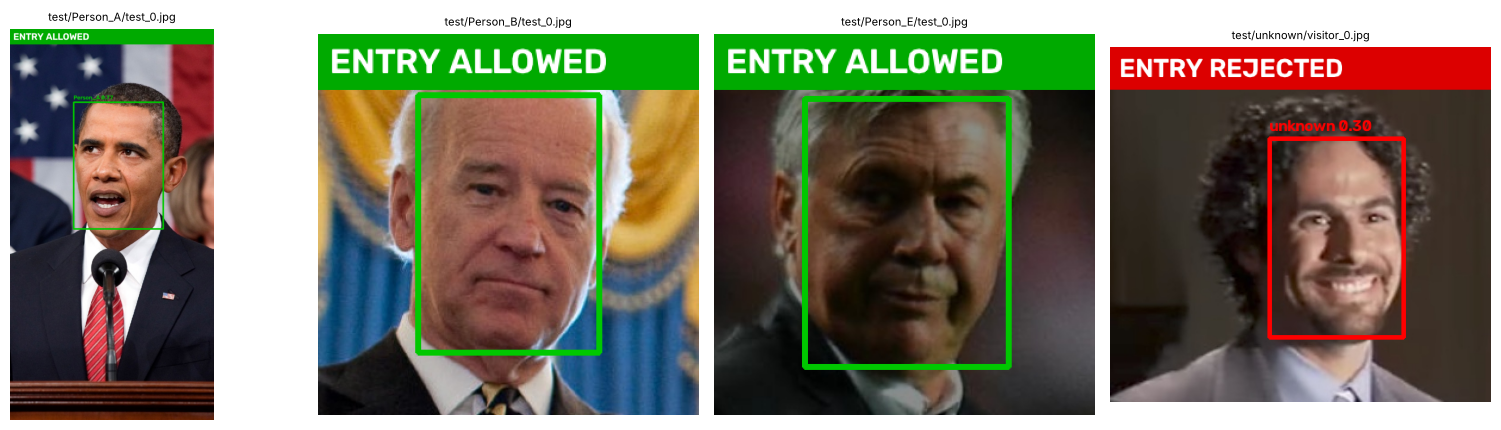

In [7]:
def identify(vec, names, gallery, threshold=THRESHOLD):
    if len(gallery) == 0:
        return "unknown", 0.0
    sims = gallery @ vec                         # cosine similarity (all vectors are unit length)
    best = int(np.argmax(sims))
    return (names[best] if sims[best] >= threshold else "unknown"), float(sims[best])

def check_entry(image, con, names, gallery, source="photo", draw=True):
    faces = engine.detect(image)
    out = image.copy()
    results = []
    for face in faces:
        name, score = identify(engine.embed(image, face), names, gallery)
        allowed = name != "unknown"
        results.append((name, score, allowed))
        log_access(con, "ALLOWED" if allowed else "REJECTED", name, score, source)
        if draw:
            x, y, w, h = face[:4].astype(int)
            colour = (0, 200, 0) if allowed else (0, 0, 255)               # BGR: green / red
            cv2.rectangle(out, (x, y), (x + w, y + h), colour, 3)
            cv2.putText(out, f"{name} {score:.2f}", (x, max(20, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colour, 2)
    if draw:                                                               # the big banner the brief asks for
        allowed_any = any(r[2] for r in results)
        text = "ENTRY ALLOWED" if allowed_any else ("ENTRY REJECTED" if results else "NO FACE - STEP CLOSER")
        colour = (0, 170, 0) if allowed_any else (0, 0, 220)
        cv2.rectangle(out, (0, 0), (out.shape[1], 46), colour, -1)
        cv2.putText(out, text, (10, 33), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    return out, results

names, gallery = load_gallery(con)
samples = [sorted(glob.glob(os.path.join(DATA, "test", n, "*")))[0] for n in ["Person_A", "Person_B", "Person_E"] if os.path.isdir(os.path.join(DATA, "test", n))]
samples += glob.glob(os.path.join(DATA, "test", "unknown", "*"))[:1]
fig, ax = plt.subplots(1, len(samples), figsize=(4 * len(samples), 4.4))
for a, path in zip(ax, samples):
    shown, res = check_entry(cv2.imread(path), con, names, gallery, source=path)
    a.imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB)); a.axis("off"); a.set_title(os.path.relpath(path, DATA), fontsize=8)
plt.tight_layout(); plt.show()

## 6 · The access log (your audit trail)

In [8]:
print(pd.read_sql("SELECT * FROM access_log ORDER BY id DESC LIMIT 8", con).to_string(index=False))

 id                time decision best_match    score                               source
  4 2026-10-22T10:55:02 REJECTED    unknown 0.304305 demo_data/test/unknown/visitor_0.jpg
  3 2026-10-22T10:55:02  ALLOWED   Person_E 0.965375   demo_data/test/Person_E/test_0.jpg
  2 2026-10-22T10:55:02  ALLOWED   Person_B 0.960718   demo_data/test/Person_B/test_0.jpg
  1 2026-10-22T10:55:02  ALLOWED   Person_A 0.768270   demo_data/test/Person_A/test_0.jpg


## 7 · Live webcam prototype

Run this on **your laptop** (not Colab), with `RUN_WEBCAM = True`. A window opens; **press `q` to quit**.

To avoid flickering decisions, the door "opens" only after the **same decision holds for several consecutive frames**, and each person is logged once per visit rather than 30 times a second.

In [9]:
RUN_WEBCAM = False
STABLE_FRAMES = 5                 # decision must be stable this many frames in a row

if RUN_WEBCAM:
    names, gallery = load_gallery(con)
    cap = cv2.VideoCapture(0)                     # 0 = built-in webcam
    history, last_logged = [], None
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        face = engine.largest_face(frame)        # the person at the door = biggest face
        if face is None:
            label, colour, history = "NO FACE - STEP CLOSER", (0, 165, 255), []
        else:
            name, score = identify(engine.embed(frame, face), names, gallery)
            history = (history + [name])[-STABLE_FRAMES:]
            stable = len(history) == STABLE_FRAMES and len(set(history)) == 1
            if stable and name != "unknown":
                label, colour = f"ENTRY ALLOWED: {name}", (0, 170, 0)
            elif stable:
                label, colour = "ENTRY REJECTED", (0, 0, 220)
            else:
                label, colour = "CHECKING...", (128, 128, 128)
            if stable and history[-1] != last_logged:
                log_access(con, "ALLOWED" if name != "unknown" else "REJECTED", name, score, "webcam")
                last_logged = history[-1]
            x, y, w, h = face[:4].astype(int)
            cv2.rectangle(frame, (x, y), (x + w, y + h), colour, 3)
        cv2.rectangle(frame, (0, 0), (frame.shape[1], 50), colour, -1)
        cv2.putText(frame, label, (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
        cv2.imshow("Smart Society Security - press q to quit", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cap.release(); cv2.destroyAllWindows()
else:
    print("Webcam demo skipped. Set RUN_WEBCAM = True on your laptop.")

Webcam demo skipped. Set RUN_WEBCAM = True on your laptop.


### Registering a resident straight from the webcam
Press **SPACE** to capture a photo (take 3–5 at slightly different angles), then **q** to save them under the given name.

In [10]:
def capture_resident(name, flat="", camera=0):
    cap = cv2.VideoCapture(camera); vectors = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        face = engine.largest_face(frame)
        view = frame.copy()
        if face is not None:
            x, y, w, h = face[:4].astype(int)
            cv2.rectangle(view, (x, y), (x + w, y + h), (255, 200, 0), 2)
        cv2.putText(view, f"{name}: {len(vectors)} captured (SPACE = capture, q = save)", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 200, 0), 2)
        cv2.imshow("Register resident", view)
        key = cv2.waitKey(1) & 0xFF
        if key == ord(" ") and face is not None:
            vectors.append(engine.embed(frame, face))
        elif key == ord("q"):
            break
    cap.release(); cv2.destroyAllWindows()
    if vectors:
        add_resident(con, name, vectors, flat=flat, sources=["webcam"] * len(vectors))
    print(f"saved {len(vectors)} faceprints for {name}")

# capture_resident("Your Name", flat="B-204")      # uncomment to use

## 8 · Evaluation: accuracy, false positives, false negatives

Put **different** photos in `data/test/<resident name>/` (people who *should* be let in) and in `data/test/unknown/` (people who should be *rejected*). For every test photo we record the decision and then count:

| | Correct decision | Wrong decision |
|---|---|---|
| **Resident** | allowed as the right person ✅ | **False negative (FN) / false reject:** resident turned away, or let in under someone else's name |
| **Unknown visitor** | rejected ✅ | **False positive (FP) / false accept:** stranger let in. **The dangerous one for security** |

- **Accuracy** = correct decisions / all decisions.
- **FAR (false acceptance rate)** = strangers let in / all strangers. Keep this near 0.
- **FRR (false rejection rate)** = residents wrongly turned away / all resident attempts. Annoying but safe.

In [11]:
def evaluate(test_dir, names, gallery, threshold):
    rows = []
    for person_dir in sorted(glob.glob(os.path.join(test_dir, "*"))):
        truth = os.path.basename(person_dir)
        for path in sorted(glob.glob(os.path.join(person_dir, "*"))):
            img = cv2.imread(path)
            face = engine.largest_face(img) if img is not None else None
            if face is None:
                pred, score = "unknown", 0.0                     # no usable face -> door stays shut
            else:
                pred, score = identify(engine.embed(img, face), names, gallery, threshold)
            rows.append({"file": os.path.relpath(path, test_dir), "truth": truth, "predicted": pred, "score": round(score, 3)})
    df = pd.DataFrame(rows)
    df["correct"] = df.truth == df.predicted
    return df

def summarize(df):
    residents = df[df.truth != "unknown"]; strangers = df[df.truth == "unknown"]
    fp = int((strangers.predicted != "unknown").sum())                  # stranger let in
    fn = int((residents.predicted != residents.truth).sum())            # resident not recognised correctly
    return {"test photos": len(df), "accuracy": df.correct.mean(),
            "false positives (strangers accepted)": fp, "FAR": fp / max(len(strangers), 1),
            "false negatives (residents rejected/misnamed)": fn, "FRR": fn / max(len(residents), 1)}

names, gallery = load_gallery(con)
results = evaluate(os.path.join(DATA, "test"), names, gallery, THRESHOLD)
summary = summarize(results)
for k, v in summary.items():
    print(f"{k:<46} {v:.1%}" if isinstance(v, float) else f"{k:<46} {v}")
print("\nmistakes:")
print(results[~results.correct].to_string(index=False) if (~results.correct).any() else "  none")

test photos                                    26
accuracy                                       100.0%
false positives (strangers accepted)           0
FAR                                            0.0%
false negatives (residents rejected/misnamed)  0
FRR                                            0.0%

mistakes:
  none


**Reading the demo result:** a perfect score on a tiny demo set is **not** proof the system is perfect. There are only 6 residents and 4 visitors, and most test photos are altered copies of the registration photo. The meaningful rows are Person_A and Person_B, whose test photos were taken on **different days**: they scored about 0.66–0.95, well above the threshold. The closest *stranger* scored 0.30, uncomfortably near 0.363. With your 20+ residents and real new photos, expect some mistakes. Report them honestly, with examples. That's what the "false positives / negatives" part of the deliverable is about.

### Choosing the threshold: the FAR vs FRR trade-off
A **higher** threshold means fewer strangers get in (lower FAR) but more residents get turned away (higher FRR). For a security gate, choose the threshold where **FAR is about 0** while FRR stays acceptable, and then go **a little higher** for a safety margin, because new strangers won't look exactly like your test visitors.

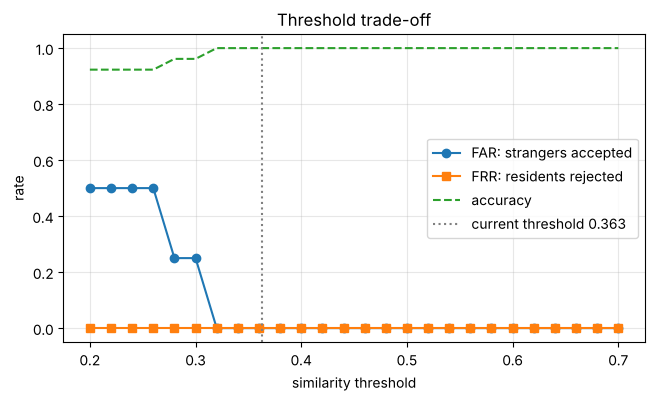

lowest threshold with FAR = 0: 0.32 (FRR there = 0.0%, accuracy 100.0%)


In [12]:
thresholds = np.round(np.arange(0.20, 0.71, 0.02), 2)
curve = []
for t in thresholds:
    s = summarize(evaluate(os.path.join(DATA, "test"), names, gallery, t))
    curve.append((t, s["FAR"], s["FRR"], s["accuracy"]))
curve = pd.DataFrame(curve, columns=["threshold", "FAR", "FRR", "accuracy"])

plt.figure(figsize=(7.5, 4))
plt.plot(curve.threshold, curve.FAR, "o-", label="FAR: strangers accepted")
plt.plot(curve.threshold, curve.FRR, "s-", label="FRR: residents rejected")
plt.plot(curve.threshold, curve.accuracy, "--", label="accuracy")
plt.axvline(THRESHOLD, color="gray", ls=":", label=f"current threshold {THRESHOLD}")
plt.xlabel("similarity threshold"); plt.ylabel("rate"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Threshold trade-off"); plt.savefig("report/threshold_tradeoff.png", dpi=120, bbox_inches="tight"); plt.show()

safe = curve[curve.FAR == 0]
if len(safe):
    best = safe.sort_values(["FRR", "threshold"]).iloc[0]
    print(f"lowest threshold with FAR = 0: {best.threshold:.2f} (FRR there = {best.FRR:.1%}, accuracy {best.accuracy:.1%})")

In [13]:
# Save everything your report needs
results.to_csv("report/test_predictions.csv", index=False)
curve.to_csv("report/threshold_sweep.csv", index=False)
with open("report/evaluation_summary.md", "w") as f:
    f.write("# Evaluation summary\n\n")
    f.write(f"- Residents in database: {con.execute('SELECT COUNT(*) FROM residents').fetchone()[0]}\n")
    f.write(f"- Threshold: {THRESHOLD}\n")
    for k, v in summary.items():
        f.write(f"- {k}: {v:.1%}\n" if isinstance(v, float) else f"- {k}: {v}\n")
print(open("report/evaluation_summary.md").read())
print("saved: report/test_predictions.csv, report/threshold_sweep.csv, report/threshold_tradeoff.png")

# Evaluation summary

- Residents in database: 6
- Threshold: 0.363
- test photos: 26
- accuracy: 100.0%
- false positives (strangers accepted): 0
- FAR: 0.0%
- false negatives (residents rejected/misnamed): 0
- FRR: 0.0%

saved: report/test_predictions.csv, report/threshold_sweep.csv, report/threshold_tradeoff.png


## 9 · What to write in your report

1. **Objective and setup:** laptop webcam, OpenCV YuNet + SFace (FaceNet-style embeddings), SQLite schema (residents, embeddings, access_log).
2. **Dataset:** number of residents (≥ 20), photos per resident, how the **test photos differ** from the registration photos (day, lighting, angle, glasses), and the number of unknown visitors.
3. **Method:** the pipeline diagram above, cosine similarity, the threshold and how you chose it (the trade-off plot), and stable-frame voting for the webcam.
4. **Results:** accuracy, FAR, FRR, the FP/FN counts table and 2–3 example mistakes with your explanation.
5. **Limitations and improvements:**
   - **Spoofing:** a printed photo or phone screen of a resident could fool it. Add **liveness detection** (blink detection, head movement, depth/IR camera).
   - **Lighting, pose, masks, glasses, ageing:** register several varied photos and re-register periodically.
   - **Small or far faces:** enforce a minimum face size (we ignore faces under `min_face` pixels).
   - **Twins and look-alikes:** that's why the threshold matters; for high security add a second factor (PIN/RFID).
   - **Privacy:** store embeddings, not photos; get consent; protect the database; delete data when residents move out.

> Using `face_recognition` (dlib) instead: `pip install face_recognition` (needs CMake and a C++ compiler on Windows), then `face_recognition.face_encodings(rgb_image)` gives 128-d vectors and `face_recognition.face_distance(known, new)` gives distances (accept if < 0.6). Everything else in this notebook (database, threshold, evaluation) stays the same.